In [1]:
# imports
import numpy as np
import pandas as pd
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
from scipy.stats import zscore
import tqdm

In [2]:
# data upload
crispr = pd.read_csv("../data_raw/depmap_crispr/CRISPRGeneEffect.csv")
expr = pd.read_csv("../data_raw/depmap_rnaseq/OmicsExpressionTPMLogp1HumanAllGenes.csv")
meta = pd.read_csv("../data_raw/depmap_metadata/Model.csv")

In [3]:
# 2. Dimension Check
print("\n--- DIMENSION CHECK ---")
for name, df in [("Metadata", meta), ("CRISPR Dependency", crispr), ("RNA-Seq Expression", expr)]:
    print(f"✅ {name:<20} | Shape: {df.shape}")


--- DIMENSION CHECK ---
✅ Metadata             | Shape: (2132, 49)
✅ CRISPR Dependency    | Shape: (1186, 18436)
✅ RNA-Seq Expression   | Shape: (1754, 60655)


In [4]:
# 3. Filtering adult glioma only models, excluding GSARC
print(meta.columns)

Index(['ModelID', 'PatientID', 'CellLineName', 'StrippedCellLineName',
       'DepmapModelType', 'OncotreeLineage', 'OncotreePrimaryDisease',
       'OncotreeSubtype', 'OncotreeCode', 'PatientSubtypeFeatures', 'RRID',
       'Age', 'AgeCategory', 'Sex', 'PatientRace', 'PrimaryOrMetastasis',
       'SampleCollectionSite', 'SourceType', 'SourceDetail', 'CatalogNumber',
       'ModelType', 'TissueOrigin', 'ModelDerivationMaterial',
       'ModelTreatment', 'PatientTreatmentStatus', 'PatientTreatmentType',
       'PatientTreatmentDetails', 'Stage', 'StagingSystem',
       'PatientTumorGrade', 'PatientTreatmentResponse', 'GrowthPattern',
       'OnboardedMedia', 'FormulationID', 'SerumFreeMedia', 'PlateCoating',
       'EngineeredModel', 'EngineeredModelDetails', 'CulturedResistanceDrug',
       'PublicComments', 'CCLEName', 'HCMIID', 'PediatricModelType',
       'ModelAvailableInDbgap', 'ModelSubtypeFeatures', 'WTSIMasterCellID',
       'SangerModelID', 'COSMICID', 'ModelIDAlias'],
      d

In [5]:
glioma_meta = meta[meta["OncotreePrimaryDisease"].str.contains("glioma", case=False, na=False)]
print("Glioma models:", glioma_meta.shape[0])

Glioma models: 96


In [6]:
exclude_terms2 = ["GSARC"]

glioma_nosarc = glioma_meta[
    ~glioma_meta["OncotreeCode"].str.contains(
        "|".join(exclude_terms2), case=False, na=False
    )
]
print("NoSarc glioma models:", glioma_nosarc.shape[0])

NoSarc glioma models: 92


In [7]:
exclude_terms = ["Unknown", "Pediatric"]

glioma_adult = glioma_nosarc[
    ~glioma_nosarc["AgeCategory"].str.contains(
        "|".join(exclude_terms), case=False, na=False
    )
]
print("Adult-like glioma models:", glioma_adult.shape[0])

Adult-like glioma models: 77


In [11]:
crispr.columns[:5]

Index(['Unnamed: 0', 'A1BG (1)', 'A1CF (29974)', 'A2M (2)', 'A2ML1 (144568)'], dtype='str')

In [12]:
expr.columns[:5]

Index(['Unnamed: 0', 'SequencingID', 'ModelID', 'IsDefaultEntryForModel',
       'ModelConditionID'],
      dtype='str')

In [13]:
glioma_ids = set(glioma_adult["ModelID"])
print(glioma_ids)

{'ACH-001214', 'ACH-000655', 'ACH-000464', 'ACH-001172', 'ACH-000269', 'ACH-000152', 'ACH-001118', 'ACH-001329', 'ACH-000075', 'ACH-000807', 'ACH-001016', 'ACH-000595', 'ACH-000376', 'ACH-000323', 'ACH-002409', 'ACH-001000', 'ACH-003438', 'ACH-000570', 'ACH-000571', 'ACH-000098', 'ACH-001623', 'ACH-000437', 'ACH-000591', 'ACH-000137', 'ACH-000215', 'ACH-002259', 'ACH-001606', 'ACH-002681', 'ACH-000631', 'ACH-002806', 'ACH-000208', 'ACH-000479', 'ACH-000368', 'ACH-000738', 'ACH-000328', 'ACH-002269', 'ACH-000329', 'ACH-000760', 'ACH-000244', 'ACH-002680', 'ACH-002223', 'ACH-000887', 'ACH-000036', 'ACH-000543', 'ACH-000819', 'ACH-000370', 'ACH-000634', 'ACH-001198', 'ACH-000504', 'ACH-001624', 'ACH-000558', 'ACH-002257', 'ACH-000027', 'ACH-000455', 'ACH-000067', 'ACH-000389', 'ACH-000040', 'ACH-000102', 'ACH-001611', 'ACH-000445', 'ACH-000469', 'ACH-000231', 'ACH-000128', 'ACH-001608', 'ACH-000883', 'ACH-001622', 'ACH-000232', 'ACH-000863', 'ACH-002225', 'ACH-001609', 'ACH-000609', 'ACH-

In [19]:
expr.columns[:5]

Index(['Unnamed: 0', 'SequencingID', 'ModelID', 'IsDefaultEntryForModel',
       'ModelConditionID'],
      dtype='str')

In [20]:
expr_glioma = expr[expr["ModelID"].isin(glioma_ids)]

In [14]:
print(crispr.shape)
crispr.head()

(1186, 18436)


,Unnamed: 0,A1BG (1),A1CF (29974),A2M (2),A2ML1 (144568),A3GALT2 (127550),A4GALT (53947),A4GNT (51146),AAAS (8086),AACS (65985),...,ZWILCH (55055),ZWINT (11130),ZXDA (7789),ZXDB (158586),ZXDC (79364),ZYG11A (440590),ZYG11B (79699),ZYX (7791),ZZEF1 (23140),ZZZ3 (26009)
0,ACH-000015,-0.101628,0.033423,-0.084998,0.084588,-0.025752,0.014998,0.127182,-0.309637,0.087638,...,-0.329088,-0.271706,0.008982,0.066563,0.130267,0.044343,-0.182709,-0.107747,-0.135141,-0.236502
1,ACH-000045,0.071876,0.096220,0.030159,0.128536,0.010489,-0.062870,-0.067315,-0.472265,-0.116420,...,-0.149970,-0.610225,0.075264,0.227191,0.011966,-0.065919,-0.171262,0.023059,-0.206351,-0.458801
2,ACH-000094,0.100488,0.204729,0.111304,0.220877,0.022709,-0.009274,0.086337,-0.224036,0.082950,...,0.014893,-0.882753,-0.238187,0.024990,-0.128601,0.359461,-0.230729,0.231520,0.042054,-0.762764
3,ACH-000096,0.182435,-0.004316,-0.117120,0.135999,-0.169988,-0.200839,0.203096,-0.027621,0.013396,...,-0.312683,-0.410344,0.199127,0.067745,0.088566,0.175735,-0.163985,-0.366537,-0.122897,-0.104066
4,ACH-000099,-0.103127,0.075134,-0.071087,0.036089,-0.016140,-0.154740,0.024042,0.045064,-0.018520,...,-0.318896,-0.603687,0.034780,0.109159,0.150058,-0.031689,-0.422116,0.127047,-0.238114,-0.257072


In [15]:
crispr = crispr.rename(columns={"Unnamed: 0": "ModelID"})

In [16]:
print(crispr.shape)
crispr.head()

(1186, 18436)


,ModelID,A1BG (1),A1CF (29974),A2M (2),A2ML1 (144568),A3GALT2 (127550),A4GALT (53947),A4GNT (51146),AAAS (8086),AACS (65985),...,ZWILCH (55055),ZWINT (11130),ZXDA (7789),ZXDB (158586),ZXDC (79364),ZYG11A (440590),ZYG11B (79699),ZYX (7791),ZZEF1 (23140),ZZZ3 (26009)
0,ACH-000015,-0.101628,0.033423,-0.084998,0.084588,-0.025752,0.014998,0.127182,-0.309637,0.087638,...,-0.329088,-0.271706,0.008982,0.066563,0.130267,0.044343,-0.182709,-0.107747,-0.135141,-0.236502
1,ACH-000045,0.071876,0.096220,0.030159,0.128536,0.010489,-0.062870,-0.067315,-0.472265,-0.116420,...,-0.149970,-0.610225,0.075264,0.227191,0.011966,-0.065919,-0.171262,0.023059,-0.206351,-0.458801
2,ACH-000094,0.100488,0.204729,0.111304,0.220877,0.022709,-0.009274,0.086337,-0.224036,0.082950,...,0.014893,-0.882753,-0.238187,0.024990,-0.128601,0.359461,-0.230729,0.231520,0.042054,-0.762764
3,ACH-000096,0.182435,-0.004316,-0.117120,0.135999,-0.169988,-0.200839,0.203096,-0.027621,0.013396,...,-0.312683,-0.410344,0.199127,0.067745,0.088566,0.175735,-0.163985,-0.366537,-0.122897,-0.104066
4,ACH-000099,-0.103127,0.075134,-0.071087,0.036089,-0.016140,-0.154740,0.024042,0.045064,-0.018520,...,-0.318896,-0.603687,0.034780,0.109159,0.150058,-0.031689,-0.422116,0.127047,-0.238114,-0.257072


In [17]:
crispr_glioma = crispr[crispr["ModelID"].isin(glioma_ids)]

In [21]:
print("CRISPR glioma:", crispr_glioma.shape)
print("Expr glioma:", expr_glioma.shape)

CRISPR glioma: (61, 18436)
Expr glioma: (69, 60655)


In [22]:
common_ids = set(crispr_glioma["ModelID"]).intersection(set(expr_glioma["ModelID"]))
print("Matched glioma lines:", len(common_ids))

Matched glioma lines: 58


In [23]:
crispr_matched = crispr_glioma[crispr_glioma["ModelID"].isin(common_ids)]
expr_matched   = expr_glioma[expr_glioma["ModelID"].isin(common_ids)]

In [24]:
print("CRISPR matched glioma:", crispr_matched.shape)
print("Expr matched glioma:", expr_matched.shape)

CRISPR matched glioma: (58, 18436)
Expr matched glioma: (60, 60655)


In [30]:
expr_id_counts = expr_matched['ModelID'].value_counts()
duplicates = expr_id_counts[expr_id_counts > 1]

print("--- DUPLICATE AUDIT ---")
if not duplicates.empty:
    print(f"⚠️ Found {len(duplicates)} duplicate IDs in the expression matrix:")
    print(duplicates)
else:
    print("✅ No duplicate IDs found.")

--- DUPLICATE AUDIT ---
⚠️ Found 2 duplicate IDs in the expression matrix:
ModelID
ACH-001172    2
ACH-000455    2
Name: count, dtype: int64


In [31]:
result = expr_matched[expr_matched['ModelID'].isin(['ACH-001172', 'ACH-000455'])]
result

,Unnamed: 0,SequencingID,ModelID,IsDefaultEntryForModel,ModelConditionID,IsDefaultEntryForMC,TSPAN6 (7105),TNMD (64102),DPM1 (8813),SCYL3 (57147),FIRRM (55732),FGR (2268),CFH (3075),FUCA2 (2519),GCLC (2729),NFYA (4800),STPG1 (90529),NIPAL3 (57185),LAS1L (81887),ENPP4 (22875),SEMA3F (6405),CFTR (1080),ANKIB1 (54467),CYP51A1 (1595),KRIT1 (889),RAD52 (5893),MYH16 (84176),BAD (572),LAP3 (51056),CD99 (4267),ENSG00000002586.20_PAR_Y,HS3ST1 (9957),AOC1 (26),WNT16 (51384),HECW1 (23072),MAD1L1 (8379),LASP1 (3927),SNX11 (29916),TMEM176A (55365),M6PR (4074),KLHL13 (90293),CYP26B1 (56603),ICA1 (3382),DBNDD1 (79007),ALS2 (57679),CASP10 (843),CFLAR (8837),TFPI (7035),NDUFAF7 (55471),RBM5 (10181),MTMR7 (9108),SLC7A2 (6542),ARF5 (381),SARM1 (23098),POLDIP2 (26073),PLXND1 (23129),AK2 (204),CD38 (952),FKBP4 (2288),KDM1A (23028),RBM6 (10180),CAMKK1 (84254),RECQL (5965),VPS50 (55610),HSPB6 (126393),ARHGAP33 (115703),NDUFAB1 (4706),PDK4 (5166),SLC22A16 (85413),ZMYND10 (51364),ABCB5 (340273),ARX (170302),SLC25A13 (10165),ST7 (7982),CDC27 (996),SLC4A1 (6521),CALCR (799),HCCS (3052),DVL2 (1856),PRSS22 (64063),UPF1 (5976),SKAP2 (8935),SLC25A5 (292),MCUB (55013),HOXA11 (3207),POLR2J (5439),DHX33 (56919),MEOX1 (4222),THSD7A (221981),LIG3 (3980),RPAP3 (79657),ACSM3 (6296),REXO5 (81691),CIAPIN1 (57019),SPPL2B (56928),ATOSB (80256),COPZ2 (51226),PRKAR2B (5577),MSL3 (10943),CREBBP (1387),TSPOAP1 (9256),MPO (4353),PON1 (5444),GCFC2 (6936),WDR54 (84058),CROT (54677),ABCB4 (5244),KMT2E (55904),RHBDD2 (57414),SOX8 (30812),IBTK (25998),ZNF195 (7748),MYCBP2 (23077),FBXL3 (26224),ITGAL (3683),PDK2 (5164),ITGA3 (3675),ZFX (7543),LAMP2 (3920),ITGA2B (3674),ASB4 (51666),GDE1 (51573),REX1BD (55049),CRLF1 (9244),OSBPL7 (114881),TMEM98 (26022),YBX2 (51087),KRT33A (3883),MAP3K14 (9020),ABCC8 (6833),CACNG3 (10368),TMEM132A (54972),AP2B1 (163),TAC1 (6863),ZNF263 (10127),CX3CL1 (6376),SPATA20 (64847),CACNA1G (8913),TNFRSF12A (51330),DLX6 (1750),MAP3K9 (4293),RALA (5898),BAIAP2L1 (55971),KDM7A (80853),ETV1 (2115),AGK (55750),ALDH3B1 (221),TTC22 (55001),PHTF2 (57157),CCL26 (10344),FARP2 (9855),USH1C (10083),GGCT (79017),DBF4 (10926),TBXA2R (6915),IFRD1 (3475),LGALS14 (56891),COX10 (1352),GTF2IRD1 (9569),PAF1 (54623),VPS41 (27072),ARHGAP44 (9912),ELAC2 (60528),SCIN (85477),ARSD (414),PNPLA4 (8228),MYH13 (8735),ADIPOR2 (79602),CDKL3 (51265),UPP2 (151531),PRSS21 (10942),MARK4 (57787),PROM1 (8842),CCDC124 (115098),CEACAM21 (90273),PAFAH1B1 (5048),NOS2 (4843),DNAH9 (1770),BLTP2 (9703),SLC13A2 (9058),GAS7 (8522),TRAPPC6A (79090),MATK (4145),CEACAM7 (1087),CD79B (974),SCN4A (6329),ST7L (54879),TKTL1 (8277),PAX6 (5080),RPUSD1 (113000),RHBDF1 (64285),LUC7L (55692),CACNA2D2 (9254),BAIAP3 (8938),TSR3 (115939),PIGQ (9091),CRAMP1 (57585),TEAD3 (7005),SELE (6401),DNAJC11 (55735),FMO3 (2328),MYLIP (29116),NOX1 (27035),E2F2 (1870),PSMB1 (5689),SYN1 (6853),JARID2 (3720),CDKL5 (6792),CAMK1G (57172),CDK11A (728642),NADK (65220),TFAP2B (7021),TFAP2D (83741),DLEC1 (9940),CYTH3 (9265),ADAM22 (53616),SYPL1 (6856),CYB561 (1534),SPAG9 (9043),CELSR3 (1951),AASS (10157),PLEKHG6 (55200),SS18L2 (51188),MPND (84954),MGST1 (4257),CRY1 (1407),PGLYRP1 (8993),NFIX (4784),ST3GAL1 (6482),MMP25 (64386),IL32 (9235),PKD1 (5310),MAPK8IP2 (23542),MED24 (9862),RHOBTB2 (23221),HEATR5B (54497),SEC62 (7095),RPS20 (6224),CSDE1 (7812),UBE3C (9690),REV3L (5980),TENM1 (10178),PAX7 (5081),MASP2 (10747),IYD (389434),FAM76A (199870),TRAF3IP3 (80342),POMT2 (29954),VTA1 (51534),MLXIPL (51085),BAZ1B (9031),RANBP9 (10048),ETV7 (51513),SPRTN (83932),METTL13 (51603),DYRK4 (8798),ZNF207 (7756),UQCRC1 (7384),STARD3NL (83930),CD9 (928),HHATL (57467),NCAPD2 (9918),IFFO1 (25900),GIPR (2696),PHF7 (51533),SEMA3G (56920),NISCH (11188),STAB1 (23166),FUZ (80199),SLC6A13 (6540),IDS (3423),PRSS3 (5646),ZNF200 (7752),CD4 (920),LRRC23 (10233),BTK (695),HFE (3077),SCMH1 (22955),FYN (2534),HIVEP2 (3097),FMO1 (2326),ELOA (6924),LYPLA2 (11313),CLCN6 (1185),MRC2 (9902),NME1-NME2 (654364),SLC6A7 (6534),TSPAN9 (10867),BTBD7 (55727),APBA3 (9546),MKS1 (54

In [32]:
expr_matched = expr_matched[expr_matched["IsDefaultEntryForMC"] == "Yes"]
print(expr_matched.shape)

(58, 60655)


In [ ]:
crispr_matched.to_csv("../data_processed/crispr_glioma_matched.csv", index=False)
expr_matched.to_csv("../data_processed/expression_glioma_matched.csv", index=False)
glioma_matched.to_csv("../data_processed/metadata_glioma_matched.csv", index=False)

In [33]:
glioma_matched   = glioma_adult[glioma_adult["ModelID"].isin(common_ids)]

In [34]:
glioma_matched ["OncotreeSubtype"].value_counts()

OncotreeSubtype
Glioblastoma              43
Astrocytoma               12
Oligodendroglioma          2
Anaplastic Astrocytoma     1
Name: count, dtype: int64

In [ ]:
# ⏱️ STEP 2: Pathway Curation & Scoring (Mean gene expression calculation)

In [35]:
expr_matched = expr_matched.set_index(expr_matched.columns[2])

In [36]:
print(expr_matched.shape)
print(expr_matched.iloc[:5, :10])

(58, 60654)
            Unnamed: 0 SequencingID IsDefaultEntryForModel ModelConditionID  \
ModelID                                                                       
ACH-000570          23   CDS-0fP9rZ                    Yes   MC-000570-eOob   
ACH-000075          90   CDS-2w7mjR                    Yes   MC-000075-5KSA   
ACH-000269          97   CDS-3KL0ED                    Yes   MC-000269-LXDZ   
ACH-000376         105   CDS-3c7zRy                    Yes   MC-000376-mBf3   
ACH-000887         150   CDS-5QvWSq                    Yes   MC-000887-cOSG   

           IsDefaultEntryForMC  TSPAN6 (7105)  TNMD (64102)  DPM1 (8813)  \
ModelID                                                                    
ACH-000570                 Yes       5.590108           0.0     6.951250   
ACH-000075                 Yes       3.531294           0.0     7.220059   
ACH-000269                 Yes       3.667699           0.0     6.589735   
ACH-000376                 Yes       3.875613         

In [37]:
expr_matched.dtypes.value_counts()

float64    60649
str            4
int64          1
Name: count, dtype: int64

In [38]:
expr_matched.select_dtypes(include="object").columns

C:\Users\oztop\AppData\Local\Temp\ipykernel_18280\2010663114.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  expr_matched.select_dtypes(include="object").columns


Index(['SequencingID', 'IsDefaultEntryForModel', 'ModelConditionID',
       'IsDefaultEntryForMC'],
      dtype='str')

In [40]:
expr_numeric = expr_matched.select_dtypes(include=["number"])
expr_numeric = expr_numeric.iloc[:, 1:] #Dropping first column which is unnamed and not gene
print(expr_numeric.shape)
print(expr_numeric.iloc[:5, :10])

(58, 60649)
            TSPAN6 (7105)  TNMD (64102)  DPM1 (8813)  SCYL3 (57147)  \
ModelID                                                               
ACH-000570       5.590108           0.0     6.951250       3.093989   
ACH-000075       3.531294           0.0     7.220059       2.084190   
ACH-000269       3.667699           0.0     6.589735       2.132554   
ACH-000376       3.875613           0.0     6.739727       2.391449   
ACH-000887       5.099859           0.0     7.046415       1.851015   

            FIRRM (55732)  FGR (2268)  CFH (3075)  FUCA2 (2519)  GCLC (2729)  \
ModelID                                                                        
ACH-000570       4.372597    0.165156    6.288552      6.830978     5.054861   
ACH-000075       3.673636    0.013002    3.490288      6.219043     4.879769   
ACH-000269       4.264063    0.039199    3.086011      6.243416     3.765641   
ACH-000376       4.395762    0.027807    5.643949      6.828746     5.181099   
ACH-000887

In [41]:
expr_numeric.columns = expr_numeric.columns.str.split(" ").str[0] #Cleaning coloumn names / genes
print("Shape of expr numeric:", expr_numeric.shape)
print(expr_numeric.columns[:10])

Shape of expr numeric: (58, 60649)
Index(['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'FIRRM', 'FGR', 'CFH', 'FUCA2',
       'GCLC', 'NFYA'],
      dtype='str')


In [42]:
gene_var = expr_numeric.var(axis=0)

keep_genes = gene_var[gene_var > gene_var.quantile(0.2)].index

expr_filtered = expr_numeric[keep_genes]

print("Filtered expression shape:", expr_filtered.shape)

Filtered expression shape: (58, 46872)


In [43]:
expr_filtered.to_csv("../data_processed/expr_filtered.csv", index=True)

In [44]:
print("Any missing values?", expr_filtered.isna().sum().sum())
print("Gene variance range:", gene_var.min(), gene_var.max())

Any missing values? 0
Gene variance range: 0.0 19.839801520127832


In [45]:
# Z-score per gene
rna_z = expr_filtered.apply(zscore)

In [46]:
import glob
import os

gmt_folder = "../data_collections//"

gmt_files = glob.glob(os.path.join(gmt_folder, "*.gmt"))

print("GMT files found:", len(gmt_files))
print(gmt_files[:5])

GMT files found: 22
['../data_collections\\GLIOMA_DNA_DAMAGE_TMZ_RESPONSE.gmt', '../data_collections\\GLIOMA_FERROPTOSIS_LIPID_STRESS.gmt', '../data_collections\\GLIOMA_IDH_EPIGENETIC_STATE.gmt', '../data_collections\\GLIOMA_MESENCHYMAL_NFKB.gmt', '../data_collections\\GLIOMA_RTK_PI3K_MAPK.gmt']


In [47]:
def load_gmt(filepath):
    """
    Loads a GMT file and returns a dictionary:
    { pathway_name : [gene1, gene2, ...] }
    """
    gene_sets = {}

    with open(filepath, "r") as f:
        for line in f:
            parts = line.strip().split("\t")

            pathway_name = parts[0]
            description  = parts[1]   # usually ignored
            genes        = parts[2:]

            gene_sets[pathway_name] = genes

    return gene_sets

In [48]:
def load_gmt(filepath):
    """
    Loads a GMT file and returns a dictionary:
    { pathway_name : [gene1, gene2, ...] }
    """
    gene_sets = {}

    with open(filepath, "r") as f:
        for line in f:
            parts = line.strip().split("\t")

            pathway_name = parts[0]
            description  = parts[1]   # usually ignored
            genes        = parts[2:]

            gene_sets[pathway_name] = genes

    return gene_sets

In [49]:
all_sets = {}

for f in gmt_files:
    gene_set = load_gmt(f)   # returns a dict with 1 pathway
    all_sets.update(gene_set)

print("Total pathways loaded:", len(all_sets))
print("Pathway names:", list(all_sets.keys()))

Total pathways loaded: 22
Pathway names: ['GLIOMA_DNA_DAMAGE_TMZ_RESPONSE', 'GLIOMA_FERROPTOSIS_LIPID_STRESS', 'GLIOMA_IDH_EPIGENETIC_STATE', 'GLIOMA_MESENCHYMAL_NFKB', 'GLIOMA_RTK_PI3K_MAPK', 'HALLMARK_ANGIOGENESIS', 'HALLMARK_APOPTOSIS', 'HALLMARK_CHOLESTEROL_HOMEOSTASIS', 'HALLMARK_DNA_REPAIR', 'HALLMARK_E2F_TARGETS', 'HALLMARK_FATTY_ACID_METABOLISM', 'HALLMARK_G2M_CHECKPOINT', 'HALLMARK_GLYCOLYSIS', 'HALLMARK_HYPOXIA', 'HALLMARK_INFLAMMATORY_RESPONSE', 'HALLMARK_MTORC1_SIGNALING', 'HALLMARK_MYC_TARGETS_V1', 'HALLMARK_OXIDATIVE_PHOSPHORYLATION', 'HALLMARK_P53_PATHWAY', 'HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY', 'HALLMARK_TNFA_SIGNALING_VIA_NFKB', 'HALLMARK_UNFOLDED_PROTEIN_RESPONSE']


In [50]:
all_sets = {}

for f in gmt_files:
    gene_set = load_gmt(f)   # returns a dict with 1 pathway
    all_sets.update(gene_set)

print("Total pathways loaded:", len(all_sets))
print("Pathway names:", list(all_sets.keys()))

Total pathways loaded: 22
Pathway names: ['GLIOMA_DNA_DAMAGE_TMZ_RESPONSE', 'GLIOMA_FERROPTOSIS_LIPID_STRESS', 'GLIOMA_IDH_EPIGENETIC_STATE', 'GLIOMA_MESENCHYMAL_NFKB', 'GLIOMA_RTK_PI3K_MAPK', 'HALLMARK_ANGIOGENESIS', 'HALLMARK_APOPTOSIS', 'HALLMARK_CHOLESTEROL_HOMEOSTASIS', 'HALLMARK_DNA_REPAIR', 'HALLMARK_E2F_TARGETS', 'HALLMARK_FATTY_ACID_METABOLISM', 'HALLMARK_G2M_CHECKPOINT', 'HALLMARK_GLYCOLYSIS', 'HALLMARK_HYPOXIA', 'HALLMARK_INFLAMMATORY_RESPONSE', 'HALLMARK_MTORC1_SIGNALING', 'HALLMARK_MYC_TARGETS_V1', 'HALLMARK_OXIDATIVE_PHOSPHORYLATION', 'HALLMARK_P53_PATHWAY', 'HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY', 'HALLMARK_TNFA_SIGNALING_VIA_NFKB', 'HALLMARK_UNFOLDED_PROTEIN_RESPONSE']


In [51]:
modules = {
    "Proliferation": ["HALLMARK_E2F_TARGETS", "HALLMARK_G2M_CHECKPOINT", "HALLMARK_MYC_TARGETS_V1"],
    "DNA_damage": ["GLIOMA_DNA_DAMAGE_TMZ_RESPONSE", "HALLMARK_DNA_REPAIR", "GLIOMA_IDH_EPIGENETIC_STATE"],
    "Growth_signaling": ["GLIOMA_RTK_PI3K_MAPK"],
    "Metabolism_glycolysis": ["HALLMARK_GLYCOLYSIS"],
    "Metabolism_OXPHOS": ["HALLMARK_OXIDATIVE_PHOSPHORYLATION"],
    "Lipid_metabolism": ["HALLMARK_CHOLESTEROL_HOMEOSTASIS", "HALLMARK_FATTY_ACID_METABOLISM"],
    "Stress_UPR_ROS": ["HALLMARK_MTORC1_SIGNALING", "HALLMARK_UNFOLDED_PROTEIN_RESPONSE", "HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY"],
    "Hypoxia": ["HALLMARK_HYPOXIA"],
    "Inflammation_TNFA": ["HALLMARK_INFLAMMATORY_RESPONSE", "HALLMARK_TNFA_SIGNALING_VIA_NFKB"],
    "Tumor_suppressor_p53": ["HALLMARK_P53_PATHWAY"],
    "Ferroptosis": ["GLIOMA_FERROPTOSIS_LIPID_STRESS"],
    "Mesenchymal_state": ["GLIOMA_MESENCHYMAL_NFKB"]
}

In [52]:
# Using z scores for this matrix as it s designed on mean
pathway_matrix = pd.DataFrame(index=rna_z.index)

MIN_GENES = 10

for pname, genes in all_sets.items():
    overlap = [g for g in genes if g in rna_z.columns]

    if len(overlap) < MIN_GENES:
        print("Skipping", pname, "- only", len(overlap), "genes found")
        continue

    pathway_matrix[pname] = rna_z[overlap].mean(axis=1)

print("Pathway matrix shape:", pathway_matrix.shape)

Pathway matrix shape: (58, 22)


In [53]:
print(pathway_matrix.iloc[:10, :15])

            GLIOMA_DNA_DAMAGE_TMZ_RESPONSE  GLIOMA_FERROPTOSIS_LIPID_STRESS  \
ModelID                                                                       
ACH-000570                        0.409142                        -0.012044   
ACH-000075                       -0.221506                         0.146176   
ACH-000269                        0.481088                        -0.711049   
ACH-000376                        0.409139                        -0.065097   
ACH-000887                        0.073347                         0.153540   
ACH-000368                       -0.063720                         0.480432   
ACH-001611                       -0.326357                         0.181122   
ACH-000098                        0.628418                         0.611452   
ACH-000760                        0.399405                         0.074991   
ACH-001610                        0.126029                        -0.289883   

            GLIOMA_IDH_EPIGENETIC_STATE  GLIOMA_MES

In [ ]:
# Feature Redundancy & VIF Testing (Pruning multicollinearity)

In [55]:
import pandas as pd

# Start from original full pathway matrix
pathways = pathway_matrix.copy()

# Create new empty module matrix
modules_df = pd.DataFrame(index=pathways.index)

# ---- Merge Proliferation ----
modules_df["Proliferation"] = pathways[
    ["HALLMARK_E2F_TARGETS",
     "HALLMARK_G2M_CHECKPOINT",
     "HALLMARK_MYC_TARGETS_V1"]
].mean(axis=1)

# ---- Merge DNA Damage ----
modules_df["DNA_Damage"] = pathways[
    ["GLIOMA_DNA_DAMAGE_TMZ_RESPONSE",
     "HALLMARK_DNA_REPAIR"]
].mean(axis=1)

# ---- Keep Single Axes ----
modules_df["Growth_Signaling"] = pathways["GLIOMA_RTK_PI3K_MAPK"]
modules_df["Glycolysis"] = pathways["HALLMARK_GLYCOLYSIS"]
modules_df["OxPhos"] = pathways["HALLMARK_OXIDATIVE_PHOSPHORYLATION"]
modules_df["Lipid_Metabolism"] = pathways[
    ["HALLMARK_FATTY_ACID_METABOLISM",
     "HALLMARK_CHOLESTEROL_HOMEOSTASIS"]
].mean(axis=1)

modules_df["Stress_UPR_ROS"] = pathways[
    ["HALLMARK_MTORC1_SIGNALING",
     "HALLMARK_UNFOLDED_PROTEIN_RESPONSE",
     "HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY"]
].mean(axis=1)

modules_df["Hypoxia"] = pathways["HALLMARK_HYPOXIA"]
modules_df["Inflammation_TNFA"] = pathways[
    ["HALLMARK_INFLAMMATORY_RESPONSE",
     "HALLMARK_TNFA_SIGNALING_VIA_NFKB"]
].mean(axis=1)

modules_df["P53"] = pathways["HALLMARK_P53_PATHWAY"]
modules_df["Ferroptosis"] = pathways["GLIOMA_FERROPTOSIS_LIPID_STRESS"]
modules_df["Mesenchymal"] = pathways["GLIOMA_MESENCHYMAL_NFKB"]
modules_df["Angiogenesis"] = pathways["HALLMARK_ANGIOGENESIS"]
modules_df["Apoptosis"] = pathways["HALLMARK_APOPTOSIS"]
modules_df["IDH_Epigenetic"] = pathways["GLIOMA_IDH_EPIGENETIC_STATE"]

In [56]:
print(modules_df.shape)
print(modules_df.columns)

(58, 15)
Index(['Proliferation', 'DNA_Damage', 'Growth_Signaling', 'Glycolysis',
       'OxPhos', 'Lipid_Metabolism', 'Stress_UPR_ROS', 'Hypoxia',
       'Inflammation_TNFA', 'P53', 'Ferroptosis', 'Mesenchymal',
       'Angiogenesis', 'Apoptosis', 'IDH_Epigenetic'],
      dtype='str')


In [57]:
# Make a copy so we don’t overwrite accidentally
modules_final = modules_df.copy()

# Drop redundant modules
modules_final = modules_final.drop(columns=["Apoptosis", "DNA_Damage"])

print("Final shape:", modules_final.shape)
print(modules_final.columns)

Final shape: (58, 13)
Index(['Proliferation', 'Growth_Signaling', 'Glycolysis', 'OxPhos',
       'Lipid_Metabolism', 'Stress_UPR_ROS', 'Hypoxia', 'Inflammation_TNFA',
       'P53', 'Ferroptosis', 'Mesenchymal', 'Angiogenesis', 'IDH_Epigenetic'],
      dtype='str')


In [ ]:
modules_final.to_csv("../data_processed/modules_final.csv", index=False)

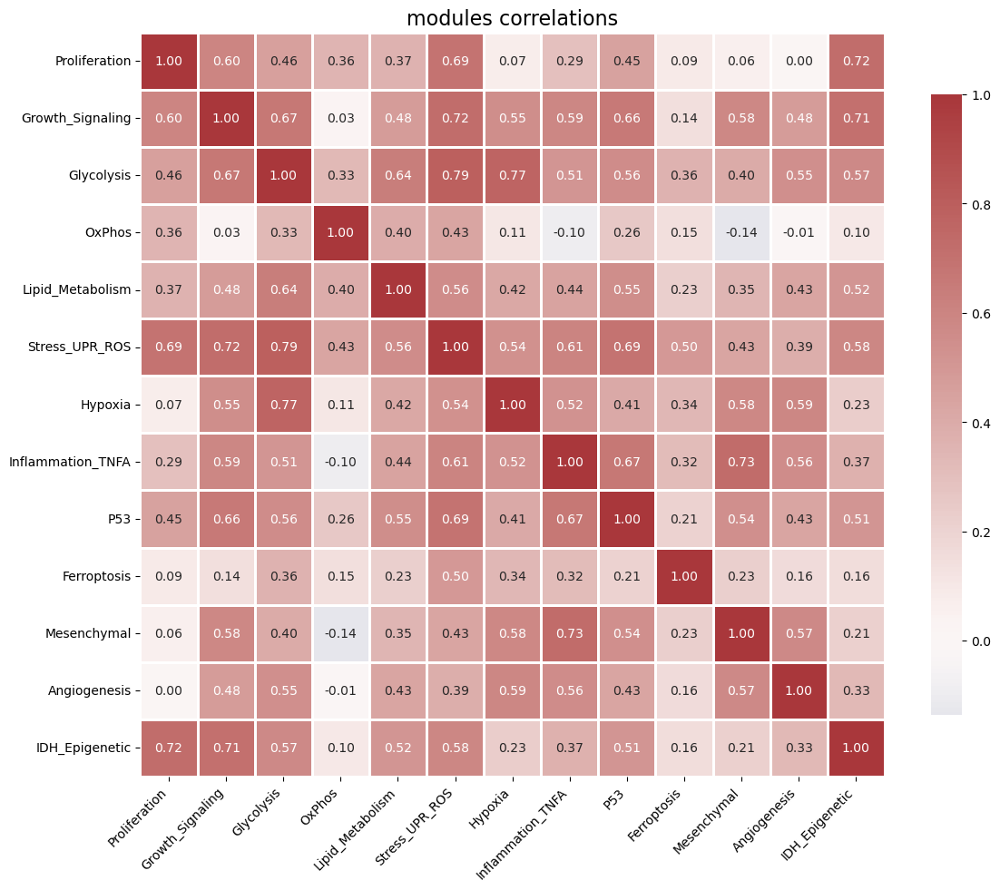

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_final = modules_final.corr()

plt.figure(figsize=(12, 10))  # Bigger figure for clarity
sns.heatmap(
    corr_final,
    cmap="vlag",
    center=0,
    square=True,
    annot=True,          # show correlation numbers
    fmt=".2f",           # 2 decimal places
    linewidths=1,        # space between cells
    cbar_kws={"shrink": 0.8}  # tidy colorbar
)

plt.title("modules correlations", fontsize=16)
plt.xticks(rotation=45, ha="right")  # rotate x-axis labels
plt.yticks(rotation=0)               # keep y-axis labels horizontal
plt.tight_layout()
plt.show()

In [59]:
import numpy as np

high_corr = []

for i in range(len(corr_final.columns)):
    for j in range(i+1, len(corr_final.columns)):
        if abs(corr_final.iloc[i,j]) > 0.8:
            high_corr.append(
                (corr_final.columns[i],
                 corr_final.columns[j],
                 corr_final.iloc[i,j])
            )

print("Highly collinear pathways:")
for pair in high_corr:
    print(pair)

Highly collinear pathways:


In [60]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

def compute_vif(df):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df)
    X_scaled = pd.DataFrame(X_scaled, columns=df.columns)

    vif_dict = {}

    for i in range(X_scaled.shape[1]):
        y = X_scaled.iloc[:, i]
        X_other = X_scaled.drop(X_scaled.columns[i], axis=1)

        model = LinearRegression()
        model.fit(X_other, y)
        r2 = model.score(X_other, y)

        vif = 1 / (1 - r2)
        vif_dict[df.columns[i]] = vif

    return pd.DataFrame({
        "Pathway": vif_dict.keys(),
        "VIF": vif_dict.values()
    }).sort_values("VIF", ascending=False)

In [61]:
vif_final = compute_vif(modules_final)
print(vif_final)

              Pathway        VIF
5      Stress_UPR_ROS  11.755779
2          Glycolysis   8.277229
0       Proliferation   6.306070
1    Growth_Signaling   5.941477
6             Hypoxia   5.029848
12     IDH_Epigenetic   4.859801
7   Inflammation_TNFA   4.296536
10        Mesenchymal   3.432981
8                 P53   3.114997
3              OxPhos   2.867761
11       Angiogenesis   2.501942
4    Lipid_Metabolism   2.410146
9         Ferroptosis   2.152410


In [ ]:
# Unsupervised K-means Clustering (k=4) on Pathway Matrix & Subtype composition in each cluster

In [63]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.stats import mannwhitneyu
import seaborn as sns
import matplotlib.pyplot as plt

In [65]:
glioma_matched = glioma_matched.set_index(glioma_matched.columns[0])
print(glioma_matched.shape)
print(glioma_matched.iloc[:5, :10])

(58, 48)
            PatientID CellLineName StrippedCellLineName DepmapModelType  \
ModelID                                                                   
ACH-000036  PT-llPs5J         U343                 U343              GB   
ACH-000040  PT-5XnRfQ     U-118 MG               U118MG            ASTR   
ACH-000067  PT-25yL7C       Hs 683                HS683             ODG   
ACH-000075  PT-59c3mE      U-87 MG                U87MG              GB   
ACH-000098  PT-HmIANs         GAMG                 GAMG              GB   

           OncotreeLineage OncotreePrimaryDisease    OncotreeSubtype  \
ModelID                                                                
ACH-000036       CNS/Brain         Diffuse Glioma       Glioblastoma   
ACH-000040       CNS/Brain         Diffuse Glioma        Astrocytoma   
ACH-000067       CNS/Brain         Diffuse Glioma  Oligodendroglioma   
ACH-000075       CNS/Brain         Diffuse Glioma       Glioblastoma   
ACH-000098       CNS/Brain       

In [66]:
X = pd.read_csv(r"C:\Users\oztop\Documents\glioma_dependency_project\data_processed\modules_final.csv", index_col=0)
print(X.iloc[:5, :10])

            Proliferation  Growth_Signaling  Glycolysis    OxPhos  \
ModelID                                                             
ACH-000570       0.130905          0.190517    0.176004  0.403816   
ACH-000075      -0.039232          0.105732    0.149200  0.235531   
ACH-000269       0.710932         -0.041958   -0.207676  0.151715   
ACH-000376       0.482456          0.135565   -0.067581  0.082954   
ACH-000887       0.121140         -0.768235   -0.317245 -0.486908   

            Lipid_Metabolism  Stress_UPR_ROS   Hypoxia  Inflammation_TNFA  \
ModelID                                                                     
ACH-000570          0.135491        0.064695  0.008740          -0.025027   
ACH-000075         -0.092404        0.181765  0.349558           0.308272   
ACH-000269         -0.302555        0.068404 -0.332766          -0.091181   
ACH-000376         -0.086693        0.203427 -0.390114           0.050270   
ACH-000887         -0.178450       -0.271766 -0.578614

In [71]:
crispr_matched = pd.read_csv(
    r"C:\Users\oztop\Documents\glioma_dependency_project\data_processed\crispr_glioma_matched.csv"
)
print(crispr_matched.shape)

(58, 18436)


In [72]:
gene_missing_frac = crispr_matched.isna().mean(axis=0)
crispr_clean = crispr_matched.loc[:, gene_missing_frac < 0.2]

print("After dropping high-missing genes:", crispr_clean.shape)

After dropping high-missing genes: (58, 17788)


In [73]:
crispr_clean = crispr_clean.set_index(crispr_clean.columns[0])
crispr_clean.columns = crispr_clean.columns.str.split(" ").str[0]
print("Shape of expr numeric:", crispr_clean.shape)
print(crispr_clean.iloc[:5, :10])

Shape of expr numeric: (58, 17787)
                A1BG      A1CF       A2M     A2ML1   A3GALT2    A4GALT  \
ModelID                                                                  
ACH-000437  0.100319 -0.017860 -0.079681  0.099179 -0.164632 -0.088770   
ACH-000592  0.115794 -0.046156 -0.013556 -0.026836 -0.118049  0.008598   
ACH-001329  0.046819  0.006580 -0.064621  0.108114 -0.134761 -0.050204   
ACH-002806  0.003001 -0.040641 -0.024673  0.108450 -0.105902 -0.075844   
ACH-000036 -0.063759  0.001143 -0.018160  0.266243 -0.118567  0.029621   

               A4GNT      AAAS      AACS     AADAC  
ModelID                                             
ACH-000437  0.100515 -0.593742 -0.121804  0.228012  
ACH-000592  0.079858 -0.861017  0.073756  0.213944  
ACH-001329  0.127441 -0.801082  0.031891  0.103424  
ACH-002806 -0.036380 -0.743151  0.146275  0.133983  
ACH-000036  0.304445 -0.626757 -0.089134  0.042882  


In [74]:
# standardize pathways for clustering
scaler = StandardScaler()
pathways_scaled = pd.DataFrame(scaler.fit_transform(X),
                               index=X.index,
                               columns=X.columns)
print(pathways_scaled.iloc[:5, :10])

            Proliferation  Growth_Signaling  Glycolysis    OxPhos  \
ModelID                                                             
ACH-000570       0.258993          0.491886    0.745450  1.176465   
ACH-000075      -0.077619          0.272985    0.631923  0.686187   
ACH-000269       1.406563         -0.108328   -0.879595  0.442001   
ACH-000376       0.954528          0.350008   -0.286233  0.241674   
ACH-000887       0.239673         -1.983467   -1.343664 -1.418541   

            Lipid_Metabolism  Stress_UPR_ROS   Hypoxia  Inflammation_TNFA  \
ModelID                                                                     
ACH-000570          0.628195        0.257308  0.035083          -0.108122   
ACH-000075         -0.428427        0.722930  1.403080           1.331817   
ACH-000269         -1.402778        0.272062 -1.335678          -0.393926   
ACH-000376         -0.401947        0.809082 -1.565867           0.217178   
ACH-000887         -0.827374       -1.080888 -2.322478

In [75]:
pca = PCA(n_components=5)  # 5 top components capture most variation
X_pca = pd.DataFrame(pca.fit_transform(pathways_scaled),
                     index=pathways_scaled.index,
                     columns=[f'PC{i+1}' for i in range(5)])

C:\Users\oztop\anaconda3\envs\pandas_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


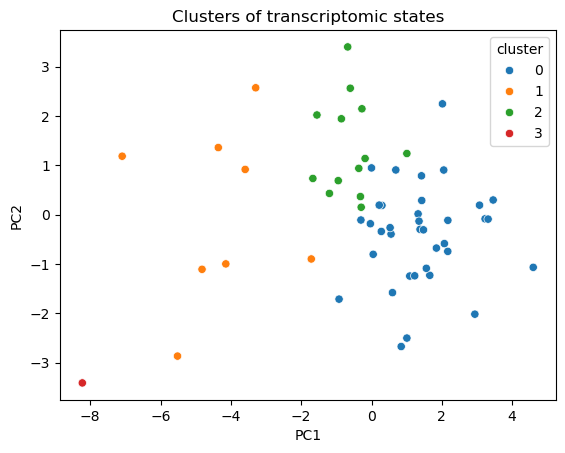

In [76]:
# choose k based on silhouette score or prior knowledge
k = 4  # e.g., 4 clusters of glioma states
kmeans = KMeans(n_clusters=k, random_state=42)
clusters = kmeans.fit_predict(X_pca)
clusters_series = pd.Series(clusters, index=X.index, name='cluster')

# visualize clusters on first two PCs
sns.scatterplot(x=X_pca['PC1'], y=X_pca['PC2'], hue=clusters_series, palette='tab10')
plt.title("Clusters of transcriptomic states")
plt.show()

In [80]:
# glioma_matched: metadata DataFrame
Subtype = glioma_matched.iloc[:,7]  # 7th column is OncotreeCode
Subtype.name = 'Subtype'

# make sure index matches your cluster assignments
Subtype.index = glioma_matched.index
Subtype.head()

ModelID
ACH-000036      GB
ACH-000040    ASTR
ACH-000067     ODG
ACH-000075      GB
ACH-000098      GB
Name: Subtype, dtype: str

In [81]:
cluster_df = pd.DataFrame({
    'Cluster': clusters_series,  # your previous clusters
    'Subtype': Subtype
})
cluster_df.head()

,Cluster,Subtype
ModelID,,
ACH-000036,0,GB
ACH-000040,0,ASTR
ACH-000067,0,ODG
ACH-000075,0,GB
ACH-000098,0,GB


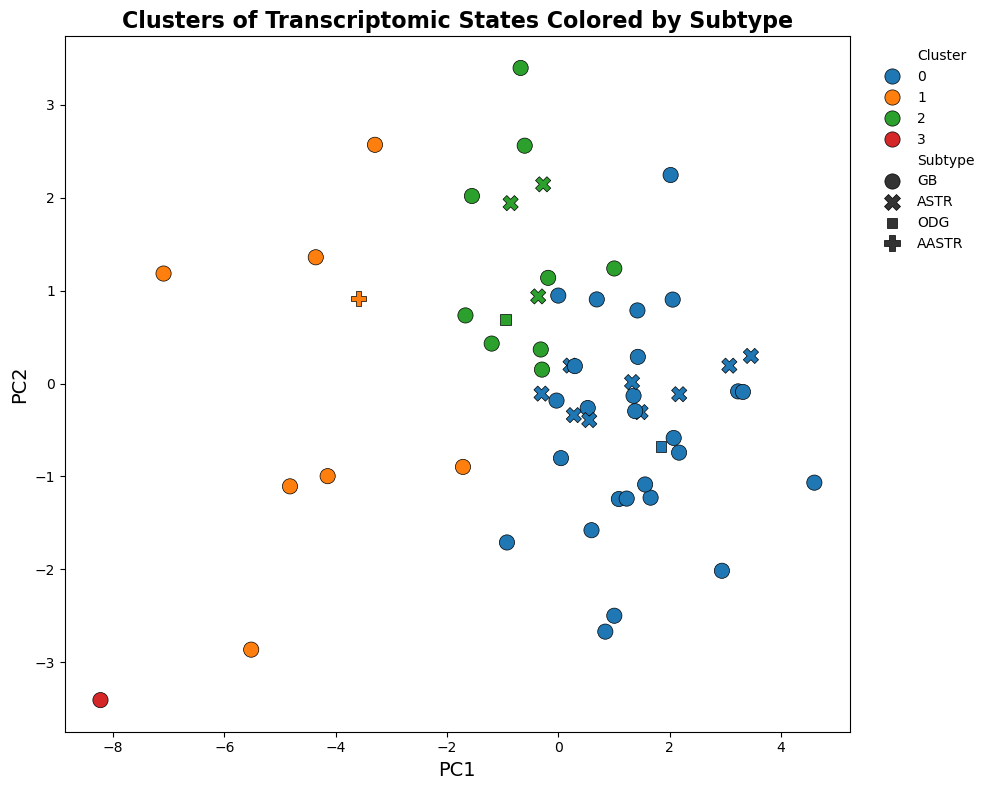

In [82]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create larger figure
plt.figure(figsize=(10,8))

# Plot
ax = sns.scatterplot(
    x=X_pca['PC1'],
    y=X_pca['PC2'],
    hue=cluster_df['Cluster'],      # color by shape
    style=cluster_df['Subtype'],    # marker subtype
    palette='tab10',
    s=120,
    edgecolor='black',
    linewidth=0.5
)

# Labels
plt.xlabel('PC1', fontsize=14)
plt.ylabel('PC2', fontsize=14)
plt.title('Clusters of Transcriptomic States Colored by Subtype', fontsize=16, weight='bold')

# Move legend outside
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=False
)

# Prevent cropping
plt.tight_layout()

# Save high-quality figures
plt.savefig(
    "transcriptomic_clusters.png",
    dpi=600,
    bbox_inches="tight"
)

# Optional: vector format for posters/papers
plt.savefig(
    "transcriptomic_clusters.svg",
    bbox_inches="tight"
)

plt.show()

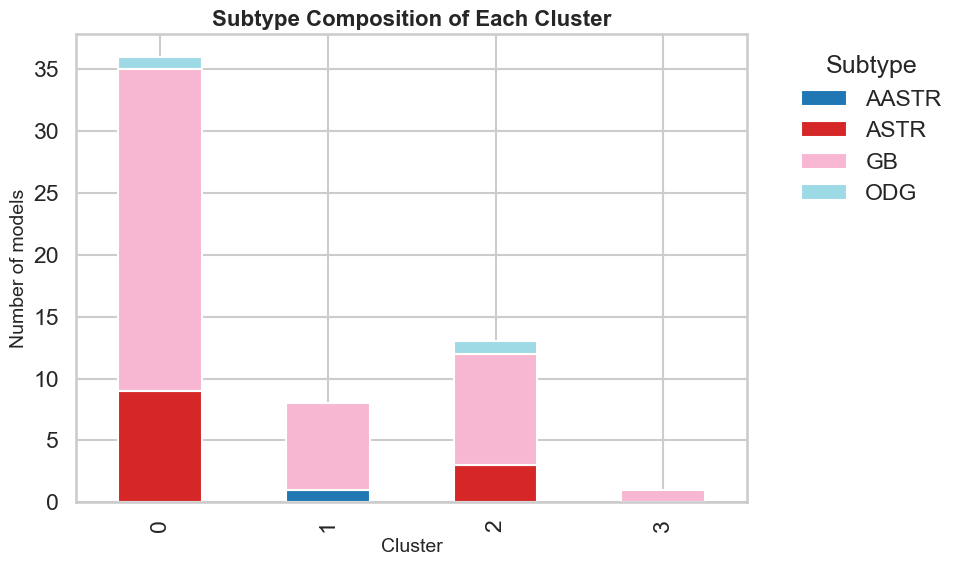

In [85]:
import matplotlib.pyplot as plt
import seaborn as sns

Subtype_counts = cluster_df.groupby(['Cluster','Subtype']).size().unstack(fill_value=0)

# Optional: seaborn style for cleaner plots
sns.set_style("whitegrid")
sns.set_context("talk")  # larger fonts

# Prepare figure
fig, ax = plt.subplots(figsize=(10,6))

# Plot stacked bar
Subtype_counts.plot(
    kind='bar',
    stacked=True,
    colormap='tab20',
    ax=ax
)

# Labels & title
ax.set_ylabel('Number of models', fontsize=14)
ax.set_xlabel('Cluster', fontsize=14)
ax.set_title('Subtype Composition of Each Cluster', fontsize=16, weight='bold')

# Move legend outside
ax.legend(
    title="Subtype",
    bbox_to_anchor=(1.05,1),
    loc='upper left',
    frameon=False
)

# Adjust layout to prevent clipping
plt.tight_layout()

# Save high-resolution figures
plt.savefig(
    "Subtype_composition_of_each_cluster.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Ranking Top 20 Selective Vulnerabilities

In [86]:
# imports
import numpy as np
import pandas as pd
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
from scipy.stats import zscore
import tqdm

In [88]:
print("Shape of crispr clean:", crispr_clean.shape)
print(crispr_clean.iloc[:5, :10])

Shape of crispr clean: (58, 17787)
                A1BG      A1CF       A2M     A2ML1   A3GALT2    A4GALT  \
ModelID                                                                  
ACH-000437  0.100319 -0.017860 -0.079681  0.099179 -0.164632 -0.088770   
ACH-000592  0.115794 -0.046156 -0.013556 -0.026836 -0.118049  0.008598   
ACH-001329  0.046819  0.006580 -0.064621  0.108114 -0.134761 -0.050204   
ACH-002806  0.003001 -0.040641 -0.024673  0.108450 -0.105902 -0.075844   
ACH-000036 -0.063759  0.001143 -0.018160  0.266243 -0.118567  0.029621   

               A4GNT      AAAS      AACS     AADAC  
ModelID                                             
ACH-000437  0.100515 -0.593742 -0.121804  0.228012  
ACH-000592  0.079858 -0.861017  0.073756  0.213944  
ACH-001329  0.127441 -0.801082  0.031891  0.103424  
ACH-002806 -0.036380 -0.743151  0.146275  0.133983  
ACH-000036  0.304445 -0.626757 -0.089134  0.042882  


In [89]:
# Identify pan-essential genes
essential_mask2 = (crispr_clean < -0.8).mean(axis=0) > 0.8
pan_essential_genes2 = crispr_clean.columns[essential_mask2]

print("Number of pan-essential genes2:", len(pan_essential_genes2))

# Remove them
crispr_filtered2 = crispr_clean.loc[:, ~essential_mask2]

print("Shape after removing pan-essential genes2:", crispr_filtered2.shape)
print(crispr_filtered2.iloc[:5, :10])

Number of pan-essential genes2: 822
Shape after removing pan-essential genes2: (58, 16965)
                A1BG      A1CF       A2M     A2ML1   A3GALT2    A4GALT  \
ModelID                                                                  
ACH-000437  0.100319 -0.017860 -0.079681  0.099179 -0.164632 -0.088770   
ACH-000592  0.115794 -0.046156 -0.013556 -0.026836 -0.118049  0.008598   
ACH-001329  0.046819  0.006580 -0.064621  0.108114 -0.134761 -0.050204   
ACH-002806  0.003001 -0.040641 -0.024673  0.108450 -0.105902 -0.075844   
ACH-000036 -0.063759  0.001143 -0.018160  0.266243 -0.118567  0.029621   

               A4GNT      AAAS      AACS     AADAC  
ModelID                                             
ACH-000437  0.100515 -0.593742 -0.121804  0.228012  
ACH-000592  0.079858 -0.861017  0.073756  0.213944  
ACH-001329  0.127441 -0.801082  0.031891  0.103424  
ACH-002806 -0.036380 -0.743151  0.146275  0.133983  
ACH-000036  0.304445 -0.626757 -0.089134  0.042882  


In [90]:
import pandas as pd
import numpy as np

# -----------------------------
# Load Chronos matrix
# rows = models
# columns = genes
# -----------------------------
Chronos = crispr_filtered2.copy()

print("Matrix shape:", Chronos.shape)

# -----------------------------
# Compute selectivity metrics
# -----------------------------
results = []

for gene in Chronos.columns:

    vals = Chronos[gene].dropna()

    median = np.median(vals)
    p10 = np.percentile(vals, 10)
    p5 = np.percentile(vals, 5)
    min_val = vals.min()

    # number of strongly dependent models
    dep_count = np.sum(vals < -0.5)

    results.append({
        "Gene": gene,
        "MedianChronos": median,
        "P10": p10,
        "P5": p5,
        "MinChronos": min_val,
        "DependentModels": dep_count
    })

results_df = pd.DataFrame(results)

# -----------------------------
# Detect selective vulnerabilities
# -----------------------------
selective = results_df[
    (results_df["MinChronos"] < -0.7) &       # strong dependency
    (results_df["DependentModels"] >= 5) &  # at least 5 glioma models
    (results_df["MedianChronos"] > -0.2)      # not pan-essential
].sort_values("MinChronos")

print(selective.head(20))

# save
selective.to_csv("glioma_selective_vulnerabilities.csv", index=False)

Matrix shape: (58, 16965)
          Gene  MedianCERES       P10        P5  MinCERES  DependentModels
13536   SMCHD1    -0.093975 -0.534241 -0.829194 -2.387371                7
3955   DNAJC19    -0.151086 -0.717277 -0.877180 -1.665241               12
4466     EP300    -0.197281 -0.690689 -0.915643 -1.637728               10
15347     TRIO    -0.141149 -0.537102 -0.681373 -1.598113                9
13698     SOX2    -0.136350 -0.490955 -0.913937 -1.525380                6
5177     FOXF1     0.023796 -0.693992 -1.178514 -1.414592                9
1167    ATP2C1    -0.184223 -0.532016 -0.747305 -1.396070                7
15238    TRAF2    -0.150568 -0.555296 -1.014785 -1.352009                8
11846   RAD51B    -0.165496 -0.524386 -0.670189 -1.347840                8
10599   PDGFRB    -0.192655 -0.504446 -0.609935 -1.345933                7
8468       MET    -0.063812 -0.796750 -0.942891 -1.341745               10
3029      COA6    -0.185506 -0.583798 -0.958775 -1.341116                9

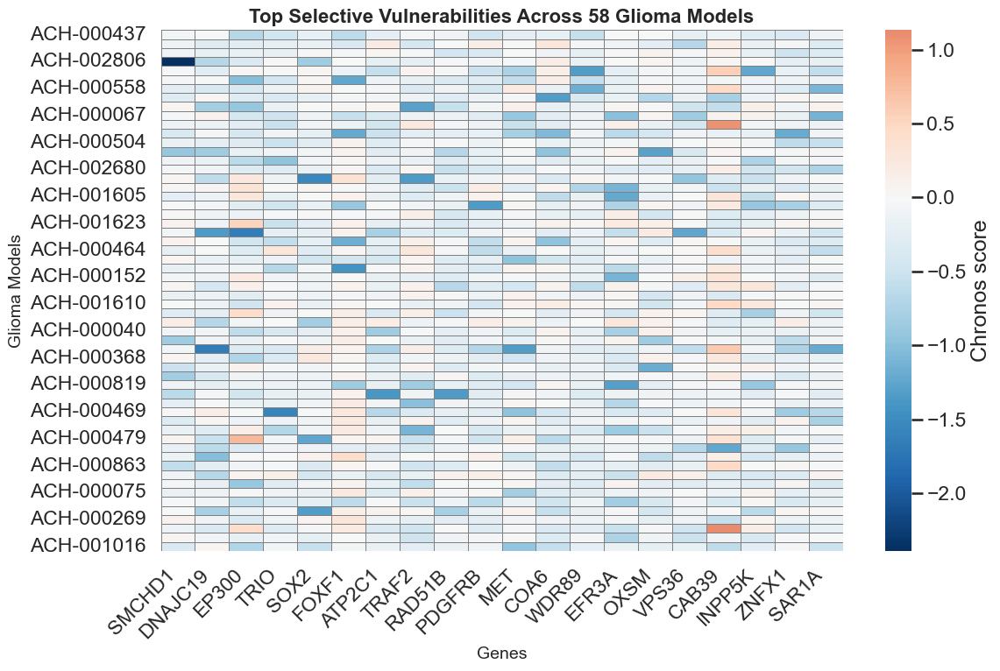

In [93]:
import seaborn as sns
import matplotlib.pyplot as plt

# Top 20 genes by MinChronos (strongest selective hits)
top_genes = selective.sort_values("MinChronos").head(20)["Gene"].tolist()

plt.figure(figsize=(12,8))
sns.heatmap(
    Chronos[top_genes], 
    cmap="RdBu_r", 
    center=0, 
    linewidths=0.5, 
    linecolor='gray',
    cbar_kws={"label": "Chronos score"}
)

plt.title("Top Selective Vulnerabilities Across 58 Glioma Models", fontsize=16, weight='bold')
plt.xlabel("Genes", fontsize=14)
plt.ylabel("Glioma Models", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

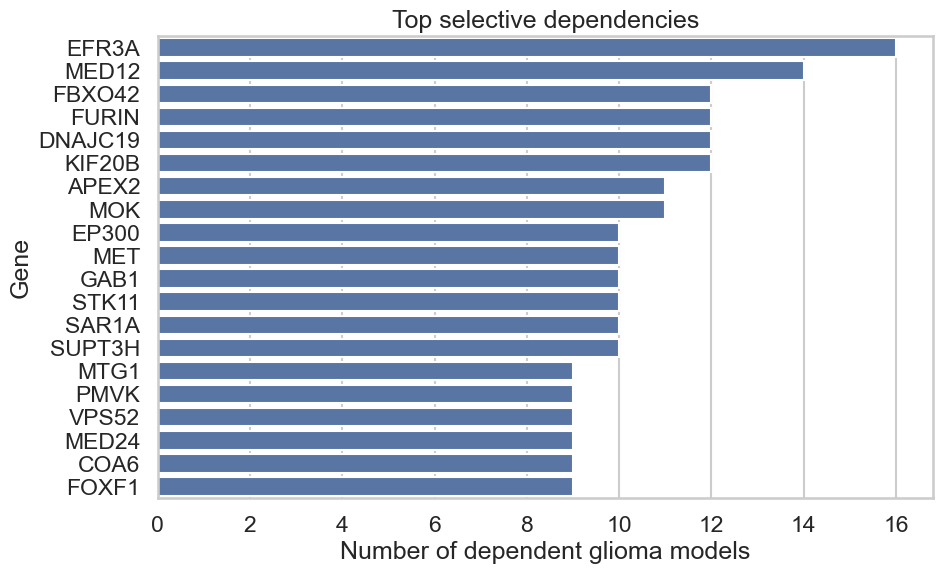

In [92]:
plt.figure(figsize=(10,6))
sns.barplot(x="DependentModels", y="Gene", data=selective.sort_values("DependentModels", ascending=False).head(20))
plt.xlabel("Number of dependent glioma models")
plt.ylabel("Gene")
plt.title("Top selective dependencies")
plt.show()

In [ ]:
# Predictive Modeling (PLSR dimensionality reduction + Logistic Regression)

In [96]:
import pandas as pd
import numpy as np

# -------------------------------
# 1. Load Chronos matrix
# -------------------------------
#Chronos = pd.read_csv("Chronos_matrix.csv", index_col=0)

# Ensure it is a DataFrame
Chronos = pd.DataFrame(Chronos)

print("Matrix shape:", Chronos.shape)

# -------------------------------
# 2. Set dependency threshold
# -------------------------------
threshold = -0.5  # Chronos < -0.5 => dependent

# -------------------------------
# 3. Convert to binary safely
# -------------------------------
binary_Chronos = Chronos.copy()  # avoid modifying original

# Use vectorized operation instead of applymap
binary_Chronos = (binary_Chronos < threshold).astype(int)

# -------------------------------
# 4. Save binary matrix
# -------------------------------
binary_Chronos.to_csv("binary_selective_vulnerabilities.csv")

print("Binary dependency matrix saved.")

Matrix shape: (58, 16965)
Binary dependency matrix saved.


In [98]:
# Define your top 53 selective vulnerabilities
candidate_genes = selective7["Gene"].to_list() 

# Make sure all genes exist in your DataFrame
candidate_genes = [g for g in candidate_genes if g in binary_Chronos.columns]
print("Using genes:", candidate_genes)

# Now select themChronos
binary_Chronos_candidate_genes = binary_Chronos[candidate_genes]
print(binary_Chronos_candidate_genes.iloc[:5, :10])
#binary_Chronos_candidate_genes.to_csv("../data_processed/candidate_genes.csv", index=True)
print("53 binary shape:", binary_Chronos_candidate_genes.shape)

Using genes: ['SMCHD1', 'DNAJC19', 'EP300', 'TRIO', 'FOXF1', 'ATP2C1', 'TRAF2', 'RAD51B', 'PDGFRB', 'MET', 'COA6', 'EFR3A', 'VPS36', 'INPP5K', 'ZNFX1', 'SAR1A', 'PRDX1', 'LCMT1', 'MED12', 'MTG1', 'STK11', 'MED24', 'PPP2R2A', 'FURIN', 'TFB1M', 'STAG2', 'SGO2', 'FBXO42', 'APEX2', 'HSPA13', 'NARS2', 'RRAGC', 'ADNP', 'GTPBP8', 'SUPT3H', 'COX4I1', 'GAB1', 'KIF20B', 'TMEM165', 'MRPS17', 'PMVK', 'GATB', 'COX10', 'VPS52', 'CHD1', 'MON2', 'FAM200B', 'MOK', 'CDIN1', 'KHDRBS1', 'CCNC', 'TRIR', 'MTERF4']
            SMCHD1  DNAJC19  EP300  TRIO  FOXF1  ATP2C1  TRAF2  RAD51B  \
ModelID                                                                  
ACH-000437       0        0      1     0      1       0      0       0   
ACH-000592       0        0      0     0      0       0      0       0   
ACH-001329       0        0      0     0      0       0      0       0   
ACH-002806       1        1      0     0      0       0      0       0   
ACH-000036       0        0      0     0      0       1   

In [108]:
import pandas as pd
import numpy as np

# pathways: models × 13
X = X.copy()

# dependencies: models × 53
Y = binary_Chronos_candidate_genes.copy()

# ensure same order
X = X.loc[Y.index]

print(X.shape)
print(Y.shape)

(58, 13)
(58, 53)


In [109]:
from sklearn.cross_decomposition import PLSRegression
from sklearn.preprocessing import StandardScaler

# scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# number of components
n_comp = 4

pls = PLSRegression(n_components=n_comp)
pls.fit(X_scaled, Y)

# latent representation of models
X_pls = pls.transform(X_scaled)

print("PLS component matrix:", X_pls.shape)

PLS component matrix: (58, 4)


In [110]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_auc_score

loo = LeaveOneOut()

gene_results = []

for gene in Y.columns:

    y = Y[gene].values

    preds = []
    truths = []

    for train_idx, test_idx in loo.split(X_pls):

        X_train, X_test = X_pls[train_idx], X_pls[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        model = LogisticRegression(
            penalty="l1",
            solver="liblinear",
            class_weight="balanced",
            max_iter=1000
        )

        model.fit(X_train, y_train)

        prob = model.predict_proba(X_test)[0,1]

        preds.append(prob)
        truths.append(y_test[0])

    auc = roc_auc_score(truths, preds)

    gene_results.append({
        "gene": gene,
        "AUROC": auc
    })

results = pd.DataFrame(gene_results).sort_values("AUROC", ascending=False)

results.head()

,gene,AUROC
42,COX10,0.835000
24,TFB1M,0.789916
39,MRPS17,0.778711
9,MET,0.747917
15,SAR1A,0.739583


In [111]:
results

,gene,AUROC
42,COX10,0.835000
24,TFB1M,0.789916
39,MRPS17,0.778711
9,MET,0.747917
15,SAR1A,0.739583
47,MOK,0.731141
4,FOXF1,0.723356
26,SGO2,0.712500
35,COX4I1,0.703081
41,GATB,0.695000


In [125]:
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample
import numpy as np

def bootstrap_auc(X, y, n_boot=200):
    aucs = []

    for i in range(n_boot):
        # 🚀 Fix 1: Pass the loop index 'i' (or any static number) as the random_state INSIDE the loop.
        # 🚀 Fix 2: Add stratify=y to guarantee both dependent and non-dependent lines are in every draw.
        X_boot, y_boot = resample(X, y, stratify=y, random_state=i)

        model = LogisticRegression(
            penalty="l1",
            solver="liblinear",
            class_weight="balanced",
            max_iter=1000
        )

        model.fit(X_boot, y_boot)

        # Predict on the original cohort to evaluate generalization stability
        probs = model.predict_proba(X)[:, 1]
        auc = roc_auc_score(y, probs)
        aucs.append(auc)

    return np.median(aucs), np.percentile(aucs, 2.5), np.percentile(aucs, 97.5)


In [126]:
bootstrap_results = []

top_genes = results.head(20)["gene"]

for gene in top_genes:

    y = Y[gene].values

    # Skip genes with only one class
    if len(np.unique(y)) < 2:
        print(f"Skipping {gene}: only one class present")
        continue

    try:
        med, lo, hi = bootstrap_auc(X_pls, y)

        bootstrap_results.append({
            "gene": gene,
            "median_auc": med,
            "ci_low": lo,
            "ci_high": hi
        })

    except ValueError as e:
        print(f"Skipping {gene}: {e}")
        continue


boot_df = pd.DataFrame(bootstrap_results)

boot_df = boot_df.sort_values("median_auc", ascending=False)

boot_df

,gene,median_auc,ci_low,ci_high
1,TFB1M,0.896359,0.803852,0.921569
0,COX10,0.885000,0.829938,0.910000
2,MRPS17,0.857143,0.770238,0.882423
3,MET,0.836458,0.757656,0.862500
9,GATB,0.830000,0.747250,0.857500
8,COX4I1,0.829132,0.784244,0.865546
4,SAR1A,0.827083,0.751771,0.852135
5,MOK,0.821083,0.746615,0.845261
10,ATP2C1,0.812325,0.669258,0.859944
11,GAB1,0.804167,0.735365,0.833385


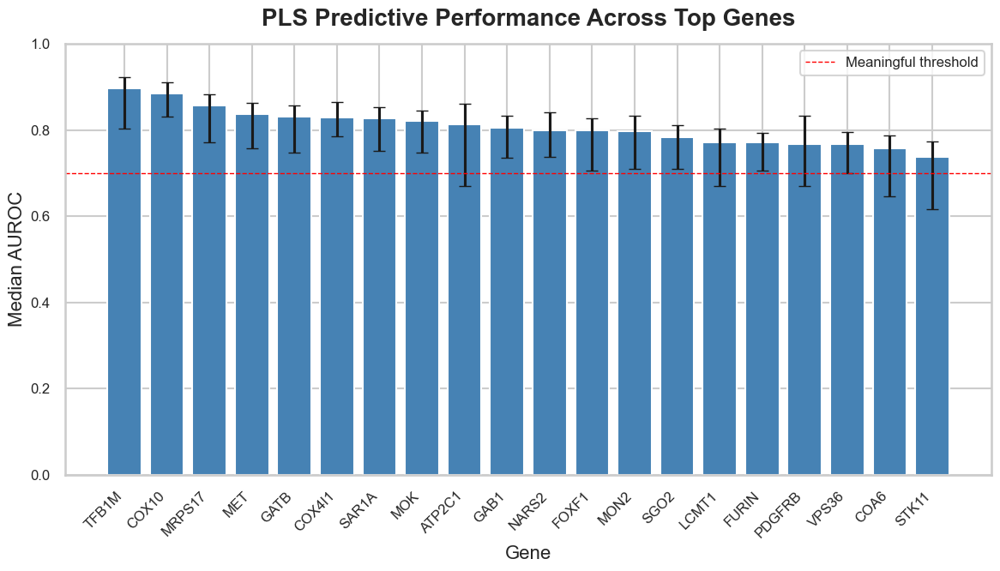

In [127]:
import matplotlib.pyplot as plt
import numpy as np

# Sort by median AUROC
boot_df = boot_df.sort_values("median_auc", ascending=False)
top_genes = boot_df["gene"]

# Color coding: highlight genes with median AUROC >= 0.7
colors = np.where(boot_df["median_auc"] >= 0.7, "steelblue", "lightgray")

# Create figure
plt.figure(figsize=(12,7))

plt.bar(
    x=top_genes,
    height=boot_df["median_auc"],
    yerr=[boot_df["median_auc"] - boot_df["ci_low"], 
          boot_df["ci_high"] - boot_df["median_auc"]],
    color=colors,
    capsize=5
)

# Labels and title
plt.ylabel("Median AUROC", fontsize=16)
plt.xlabel("Gene", fontsize=16)
plt.title("PLS Predictive Performance Across Top Genes", fontsize=20, weight='bold', pad=15)

# Tick formatting
plt.xticks(rotation=45, ha="right", fontsize=12)
plt.yticks(fontsize=12)

# Y-axis limits
plt.ylim(0,1)

# Optional: horizontal line at AUROC=0.7
plt.axhline(0.7, color='red', linestyle='--', linewidth=1, label="Meaningful threshold")

# Legend for threshold
plt.legend(fontsize=12)

# Layout adjustment
plt.tight_layout()

# Save high-resolution figures
plt.savefig("PLS_Bootstrap_AUROC_TopGenes.png", dpi=600, bbox_inches="tight")
plt.savefig("PLS_Bootstrap_AUROC_TopGenes.svg", bbox_inches="tight")

plt.show()

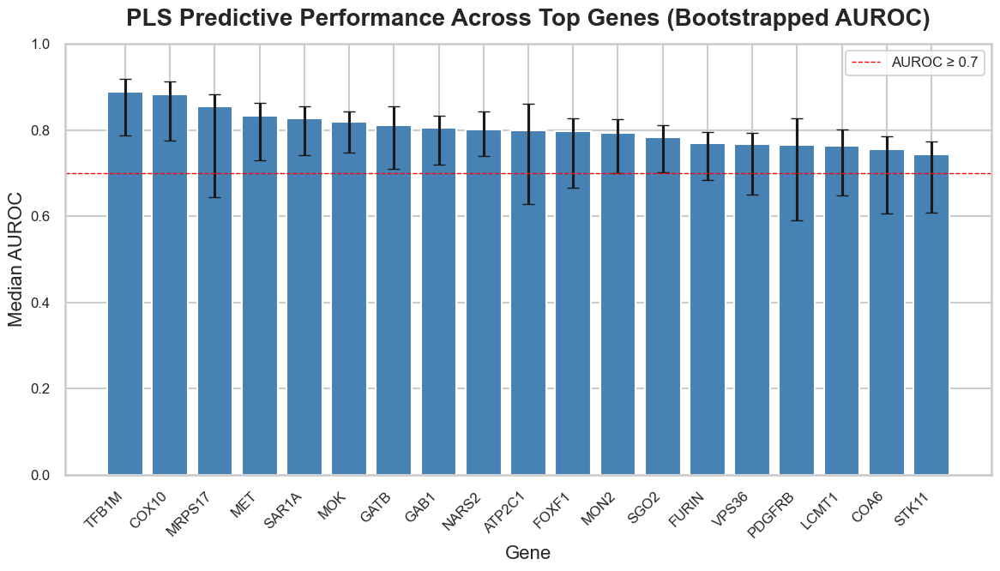

In [115]:
import matplotlib.pyplot as plt
import numpy as np

# Sort bootstrapped results by median AUROC
boot_df = boot_df.sort_values("median_auc", ascending=False)
top_genes = boot_df["gene"]

# Color: highlight genes with median AUROC >= 0.7
colors = np.where(boot_df["median_auc"] >= 0.7, "steelblue", "lightgray")

# Create figure
plt.figure(figsize=(12,7))

plt.bar(
    x=top_genes,
    height=boot_df["median_auc"],
    yerr=[boot_df["median_auc"] - boot_df["ci_low"], 
          boot_df["ci_high"] - boot_df["median_auc"]],
    color=colors,
    capsize=5
)

# Labels and title
plt.ylabel("Median AUROC", fontsize=16)
plt.xlabel("Gene", fontsize=16)
plt.title("PLS Predictive Performance Across Top Genes (Bootstrapped AUROC)", fontsize=20, weight='bold', pad=15)

# Tick formatting
plt.xticks(rotation=45, ha="right", fontsize=12)
plt.yticks(fontsize=12)

# Y-axis limits
plt.ylim(0,1)

# Optional horizontal line for meaningful threshold
plt.axhline(0.7, color='red', linestyle='--', linewidth=1, label="AUROC ≥ 0.7")
plt.legend(fontsize=12)

# Layout adjustment
plt.tight_layout()

# Save high-resolution figures
plt.savefig("PLS_Bootstrap_AUROC_TopGenes.png", dpi=600, bbox_inches="tight")
plt.savefig("PLS_Bootstrap_AUROC_TopGenes.svg", bbox_inches="tight")

plt.show()

In [ ]:
# Stability & Biological Interpretation (Bootstrap AUROCs & Loading plots)

In [116]:
pls_loadings = pd.DataFrame(
    pls.x_weights_,
    index=X.columns,
    columns=[f"PLS{i+1}" for i in range(n_comp)]
)

pls_loadings

,PLS1,PLS2,PLS3,PLS4
Proliferation,0.061620,0.490931,-0.311980,-0.214000
Growth_Signaling,0.330088,0.059638,-0.264765,-0.239338
Glycolysis,0.210235,0.231173,0.202625,-0.003784
OxPhos,-0.097487,0.523672,0.357935,0.331001
Lipid_Metabolism,0.234940,0.160150,0.612338,-0.405207
Stress_UPR_ROS,0.270845,0.339568,-0.100615,0.190534
Hypoxia,0.262982,-0.088966,0.370023,0.025185
Inflammation_TNFA,0.431815,-0.130977,-0.188826,0.101948
P53,0.341251,0.084357,-0.034689,0.028290
Ferroptosis,0.132640,0.156133,-0.074162,0.672545


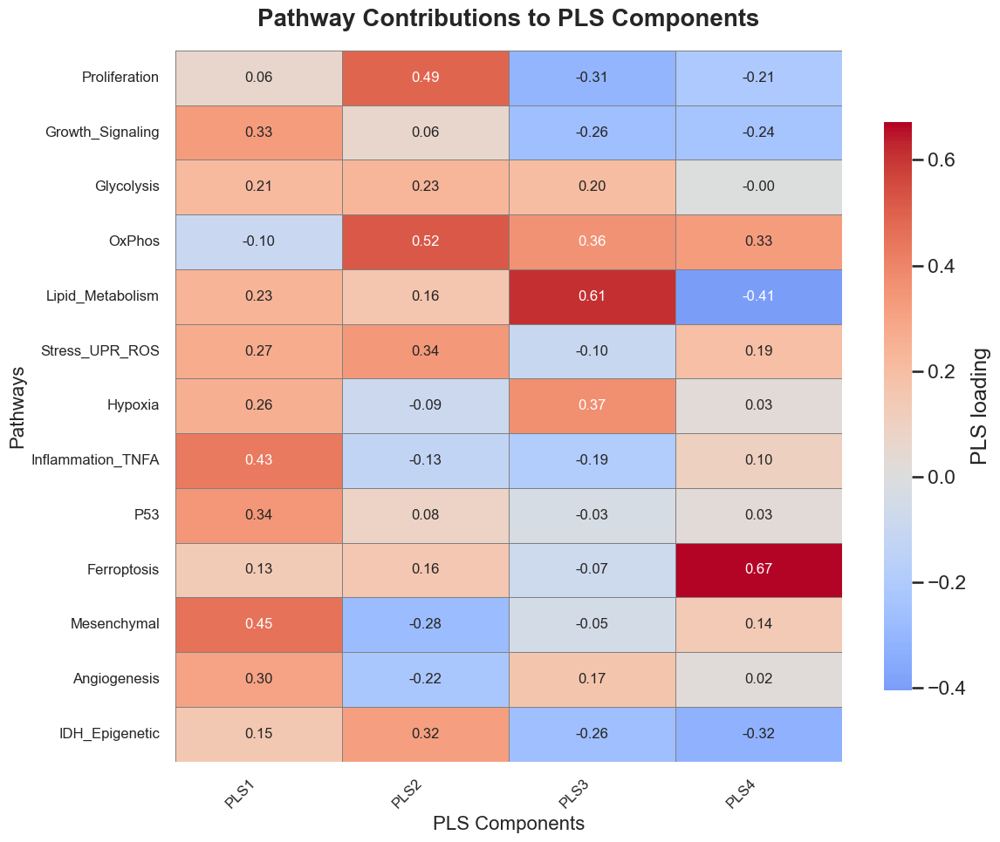

In [118]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create figure
plt.figure(figsize=(12,10))  # larger for poster

# Poster-ready heatmap with values in cells
sns.heatmap(
    pls_loadings,
    cmap="coolwarm",
    center=0,
    annot=True,           # show values in cells
    fmt=".2f",            # 2 decimal places
    annot_kws={"size":12}, # font size for cell annotations
    linewidths=0.5,
    linecolor="gray",
    cbar_kws={"label": "PLS loading", "shrink":0.8}
)

# Labels and title
plt.title("Pathway Contributions to PLS Components", fontsize=20, weight='bold', pad=20)
plt.xlabel("PLS Components", fontsize=16)
plt.ylabel("Pathways", fontsize=16)

# Tick formatting
plt.xticks(rotation=45, ha="right", fontsize=12)
plt.yticks(rotation=0, fontsize=12)

# Layout adjustment
plt.tight_layout()

# Save high-resolution figure
plt.savefig("PLS_Pathway_Contributions.png", dpi=600, bbox_inches='tight')
plt.savefig("PLS_Pathway_Contributions.svg", bbox_inches='tight')

plt.show()

In [119]:
for comp in pls_loadings.columns:
    print("\n", comp)
    print(pls_loadings[comp].abs().sort_values(ascending=False).head(5))


 PLS1
Mesenchymal          0.449510
Inflammation_TNFA    0.431815
P53                  0.341251
Growth_Signaling     0.330088
Angiogenesis         0.301294
Name: PLS1, dtype: float64

 PLS2
OxPhos            0.523672
Proliferation     0.490931
Stress_UPR_ROS    0.339568
IDH_Epigenetic    0.317242
Mesenchymal       0.282144
Name: PLS2, dtype: float64

 PLS3
Lipid_Metabolism    0.612338
Hypoxia             0.370023
OxPhos              0.357935
Proliferation       0.311980
Growth_Signaling    0.264765
Name: PLS3, dtype: float64

 PLS4
Ferroptosis         0.672545
Lipid_Metabolism    0.405207
OxPhos              0.331001
IDH_Epigenetic      0.320989
Growth_Signaling    0.239338
Name: PLS4, dtype: float64


In [120]:
import pandas as pd

# Initialize list to store results
top_loadings_list = []

# Loop over each PLS component
for comp in pls_loadings.columns:
    # Sort absolute values descending and take top 5
    top_features = pls_loadings[comp].abs().sort_values(ascending=False).head(5)
    
    # Store in a list of dicts
    for feature, value in top_features.items():
        top_loadings_list.append({
            "Component": comp,
            "Feature": feature,
            "Absolute_Loading": value,
            "Signed_Loading": pls_loadings.loc[feature, comp]  # optional: keep sign
        })

# Convert to DataFrame
top_loadings_df = pd.DataFrame(top_loadings_list)

# Preview
print(top_loadings_df)

# Save to CSV
top_loadings_df.to_csv("PLS_Top5_Loadings_per_Component.csv", index=False)

   Component            Feature  Absolute_Loading  Signed_Loading
0       PLS1        Mesenchymal          0.449510        0.449510
1       PLS1  Inflammation_TNFA          0.431815        0.431815
2       PLS1                P53          0.341251        0.341251
3       PLS1   Growth_Signaling          0.330088        0.330088
4       PLS1       Angiogenesis          0.301294        0.301294
5       PLS2             OxPhos          0.523672        0.523672
6       PLS2      Proliferation          0.490931        0.490931
7       PLS2     Stress_UPR_ROS          0.339568        0.339568
8       PLS2     IDH_Epigenetic          0.317242        0.317242
9       PLS2        Mesenchymal          0.282144       -0.282144
10      PLS3   Lipid_Metabolism          0.612338        0.612338
11      PLS3            Hypoxia          0.370023        0.370023
12      PLS3             OxPhos          0.357935        0.357935
13      PLS3      Proliferation          0.311980       -0.311980
14      PL

C:\Users\oztop\AppData\Local\Temp\ipykernel_18280\39668145.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pathway_contrib.values, y=pathway_contrib.index, palette="coolwarm")


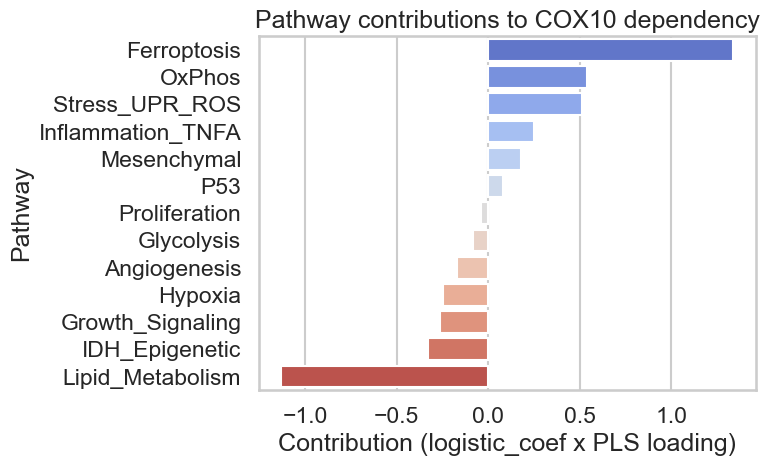

C:\Users\oztop\AppData\Local\Temp\ipykernel_18280\39668145.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pathway_contrib.values, y=pathway_contrib.index, palette="coolwarm")


<Figure size 640x480 with 0 Axes>

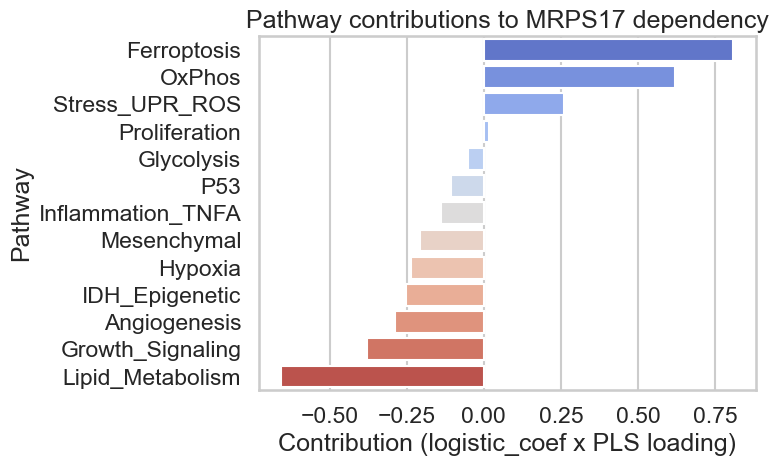

C:\Users\oztop\AppData\Local\Temp\ipykernel_18280\39668145.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pathway_contrib.values, y=pathway_contrib.index, palette="coolwarm")


<Figure size 640x480 with 0 Axes>

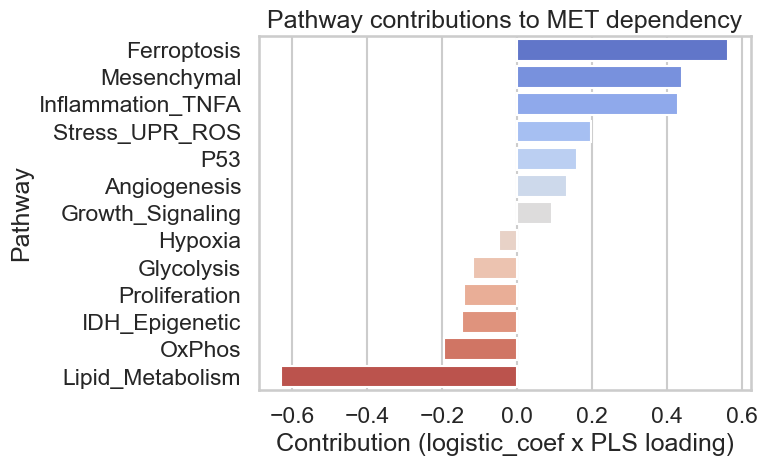

<Figure size 640x480 with 0 Axes>

In [121]:
# ==========================================
# Ready-to-run snippet for top 3 genes
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression

# --- Top genes ---
top_genes = ["COX10", "MRPS17", "MET"]

# --- PLS loadings from previous step ---
# pls_loadings: pathways x PLS components (13 x 4)
# X_pls: 58 x 4 latent components for models
# Y: 58 x 53 binary dependency matrix
# Ensure top genes exist in Y.columns
top_genes = [g for g in top_genes if g in Y.columns]

for gene in top_genes:

    y = Y[gene].values

    # Train logistic regression on PLS components
    model = LogisticRegression(
        penalty="l1", solver="liblinear", class_weight="balanced", max_iter=1000
    )
    model.fit(X_pls, y)

    coef = pd.Series(model.coef_[0], index=[f"PLS{i+1}" for i in range(X_pls.shape[1])])

    # Map logistic coefficients back to pathway space
    # Contribution = coef (PLS) * pls_loadings (pathway x PLS)
    pathway_contrib = pls_loadings.dot(coef)

    # Sort for visualization
    pathway_contrib = pathway_contrib.sort_values(ascending=False)

    # --- Plot ---
    plt.figure(figsize=(8,5))
    sns.barplot(x=pathway_contrib.values, y=pathway_contrib.index, palette="coolwarm")
    plt.title(f"Pathway contributions to {gene} dependency")
    plt.xlabel("Contribution (logistic_coef x PLS loading)")
    plt.ylabel("Pathway")
    plt.tight_layout()
    plt.show()

    plt.savefig("PLS_Pathway_Contributions.png", dpi=600, bbox_inches='tight')